# Pairs Trading with Cointegration: Japanese Stocks
**Author:** Silam Shrestha

**Idea:** two similar companies (for example two big banks) tend to move together. When the gap between them becomes unusually wide, bet that it will close.

**Key concept: cointegration, not correlation.** Correlation means returns move together day to day. Cointegration means the **prices stay tied in the long run**, so the gap (spread) keeps coming back to its average. Only cointegration supports this strategy.

**Method:** choose the pair and hedge ratio on **2015–2019**, then trade it on **2020–2025** without changes.

## Step 1. Tools

In [1]:
!pip install yfinance statsmodels -q
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

## Step 2. Candidate pairs (same industry)
| Pair | Industry |
|---|---|
| MUFG (8306) / SMFG (8316) | Banks |
| NTT (9432) / KDDI (9433) | Telecom |
| Mitsubishi Corp (8058) / Mitsui & Co (8031) | Trading houses |
| Toyota (7203) / Honda (7267) | Cars |

In [2]:
PAIRS = [("8306.T", "8316.T"), ("9432.T", "9433.T"), ("8058.T", "8031.T"), ("7203.T", "7267.T")]
TICKERS = sorted({t for p in PAIRS for t in p})
FORM_START, FORM_END, TRADE_END = "2015-01-01", "2019-12-31", "2025-12-31"
ENTRY_Z, EXIT_Z, STOP_Z, COST = 2.0, 0.5, 4.0, 0.0010

raw = yf.download(TICKERS, start=FORM_START, end=TRADE_END, auto_adjust=True, progress=False)
prices = raw["Close"].dropna()
if prices.empty:
    raise RuntimeError("No data downloaded. Check internet and run again.")
logp = np.log(prices)
form, trade = logp.loc[:FORM_END], logp.loc[FORM_END:].iloc[1:]
print(prices.shape)

(2709, 8)


## Step 3. Test cointegration on the formation period
Engle-Granger test: **p-value below 0.05** suggests the pair is cointegrated.

⚠️ Testing 4 pairs means one might pass by luck. With many pairs you should correct for multiple testing.

In [3]:
rows = []
for a, b in PAIRS:
    t_stat, p_value, _ = coint(form[a], form[b])
    beta = sm.OLS(form[a], sm.add_constant(form[b])).fit().params[b]
    rows.append({"pair": f"{a} / {b}", "a": a, "b": b, "p_value": p_value, "hedge_ratio": beta})
tests = pd.DataFrame(rows).sort_values("p_value")
tests

,pair,a,b,p_value,hedge_ratio
1,9432.T / 9433.T,9432.T,9433.T,0.112626,1.277952
2,8058.T / 8031.T,8058.T,8031.T,0.180599,1.224354
0,8306.T / 8316.T,8306.T,8316.T,0.802309,1.082450
3,7203.T / 7267.T,7203.T,7267.T,0.837934,0.688967


## Step 4. Build the spread and z-score
- **Hedge ratio (β):** from a regression of log price A on log price B. Spread = log A − β × log B.
- **z-score** = (spread − its formation mean) ÷ its formation standard deviation. It tells us how unusual today's gap is.

Mean and standard deviation come only from 2015–2019, so the trading period uses no future information.

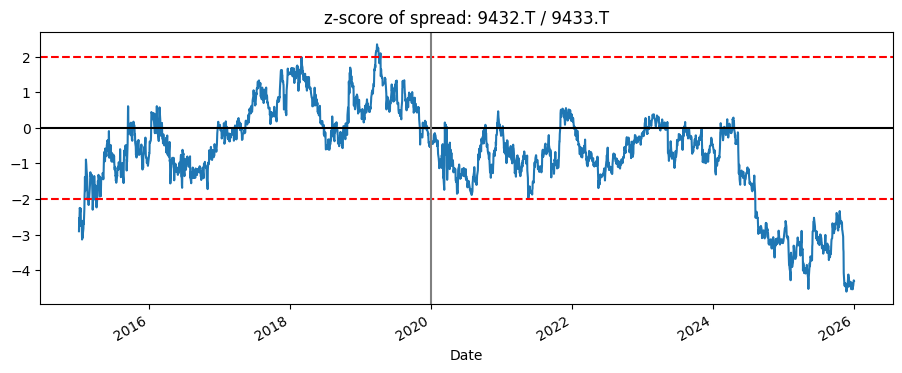

In [4]:
def zscore_series(a, b, beta):
    spread_form = form[a] - beta * form[b]
    mu, sd = spread_form.mean(), spread_form.std()
    full = logp[a] - beta * logp[b]
    return (full - mu) / sd

best = tests.iloc[0]
z = zscore_series(best.a, best.b, best.hedge_ratio)
z.plot(figsize=(11, 4), title=f"z-score of spread: {best.pair}")
for lvl in [ENTRY_Z, -ENTRY_Z]: plt.axhline(lvl, color="red", linestyle="--")
plt.axhline(0, color="black"); plt.axvline(pd.Timestamp(FORM_END), color="grey")
plt.show()

## Step 5. Trading rules
- z > +2: spread too **wide**, so **sell** A and **buy** β of B (position −1).
- z < −2: spread too **narrow**, so **buy** A and **sell** β of B (position +1).
- Exit when |z| < 0.5 (gap closed). **Stop-loss** if |z| > 4 (the relationship may have broken).
- After a stop-loss, **no new trade** until |z| comes back below 2. Without this rule the strategy would re-enter the next day and get stopped out again and again, paying costs each time.
- Today's position is decided with **yesterday's** z-score.

In [5]:
def backtest_pair(a, b, beta):
    z = zscore_series(a, b, beta).loc[trade.index]
    pos, state, blocked, stops = [], 0, False, 0
    for val in z:
        if blocked and abs(val) < ENTRY_Z:
            blocked = False
        if state == 0:
            if not blocked and abs(val) <= STOP_Z:
                state = -1 if val > ENTRY_Z else (1 if val < -ENTRY_Z else 0)
        elif abs(val) < EXIT_Z:
            state = 0
        elif abs(val) > STOP_Z:
            state, blocked, stops = 0, True, stops + 1
        pos.append(state)
    stop_counts[(a, b)] = stops
    pos = pd.Series(pos, index=z.index).shift(1).fillna(0)
    ra, rb = prices[a].pct_change().loc[z.index], prices[b].pct_change().loc[z.index]
    spread_ret = (ra - beta * rb) / (1 + abs(beta))
    pnl = pos * spread_ret - pos.diff().abs().fillna(0) * COST
    return pnl.fillna(0), pos

def perf(r, periods=252):
    r = r.dropna()
    cum = (1 + r).cumprod()
    return pd.Series({
        "Annual return": r.mean() * periods,
        "Annual volatility": r.std() * np.sqrt(periods),
        "Sharpe": (r.mean() / r.std()) * np.sqrt(periods),
        "Max drawdown": (cum / cum.cummax() - 1).min(),
    })

results, positions, stop_counts = {}, {}, {}
for _, row in tests.iterrows():
    pnl, pos = backtest_pair(row.a, row.b, row.hedge_ratio)
    results[row.pair], positions[row.pair] = pnl, pos
summary = pd.DataFrame({k: perf(v) for k, v in results.items()}).T
summary["Days in a trade"] = [(positions[k] != 0).mean() for k in summary.index]
summary["Formation p-value"] = tests.set_index("pair").loc[summary.index, "p_value"].values
summary["Stop-losses hit"] = [stop_counts[(r.a, r.b)] for _, r in tests.set_index("pair").loc[summary.index].reset_index().iterrows()]
summary

,Annual return,Annual volatility,Sharpe,Max drawdown,Days in a trade,Formation p-value,Stop-losses hit
9432.T / 9433.T,-0.011444,0.022829,-0.501304,-0.069096,0.080601,0.112626,1
8058.T / 8031.T,-0.002320,0.021695,-0.106921,-0.064499,0.071038,0.180599,1
8306.T / 8316.T,0.026511,0.039211,0.676114,-0.048076,0.360656,0.802309,0
7203.T / 7267.T,-0.015270,0.060775,-0.251258,-0.138236,0.232240,0.837934,1


## Step 6. Plot trading-period results (2020–2025)

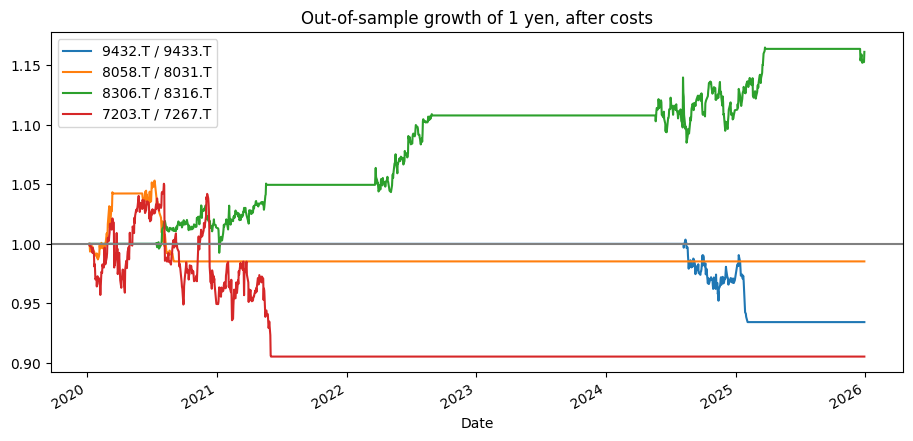

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
for k, v in results.items():
    (1 + v).cumprod().plot(ax=ax, label=k)
ax.axhline(1, color="grey"); ax.legend(); ax.set_title("Out-of-sample growth of 1 yen, after costs")
plt.show()

## Step 7. Conclusions
1. **No pair was cointegrated in 2015–2019 at the 5% level.** The closest were NTT/KDDI (p = 0.11) and Mitsubishi Corp/Mitsui (p = 0.18); MUFG/SMFG (p = 0.80) and Toyota/Honda (p = 0.84) were far from it. So the statistical basis for pairs trading was weak from the start.
2. **Out of sample (2020–2025), results were small and mostly negative after costs.** Sharpe ratios: NTT/KDDI −0.50, Mitsubishi/Mitsui −0.11, Toyota/Honda −0.25. Only MUFG/SMFG was positive (Sharpe 0.68, 2.7% a year), but it was the *least* cointegrated pair, so this is most likely luck rather than a real edge.
3. **Three of the four pairs hit their stop-loss once,** meaning the spread moved more than 4 standard deviations from its 2015–2019 average. Relationships between companies change: different business mixes (for example Toyota's hybrids versus Honda's motorcycles), different exposure to interest rates or commodities, and events such as large shareholder purchases can permanently shift a spread.
4. **Fixing a backtest bug mattered.** My first version re-entered a trade the day after every stop-loss, so it was stopped out repeatedly and paid costs each time. That turned small losses into a −25% annual loss for one pair. Blocking re-entry until the spread returns below 2 standard deviations fixed this.

**Conclusion:** in this sample, these same-industry pairs did not offer a reliable pairs-trading edge. Being in the same industry is not enough; a pair needs evidence of a stable long-run relationship.

**Limitations:** only four pairs; a fixed hedge ratio (it can drift over time); simplified costs; short-selling costs in Japan ignored; cointegration found in the past may not last.